# Proyek Analisis Data: E-Commerce Public Dataset (Olist)

- **Nama:** Angger Raka Sanjaya
- **Email:** anggerrakasanjayapamungkas@gmail.com
- **ID Dicoding:** anggerraka

Dataset: **E-Commerce Public Dataset (Brazilian Olist)**


## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

### Jawaban

**Pertanyaan 1** 
**Kategori produk & metode pembayaran penyumbang pendapatan**
*Kategori produk apa dan metode pembayaran apa yang menyumbang nilai transaksi tertinggi pada order berstatus `delivered` sepanjang periode data Olist (September 2016 – Oktober 2018), dan bagaimana komposisinya?*

- **Specific:** fokus pada kontribusi pendapatan per kategori produk dan per metode pembayaran, bukan "penjualan" secara umum.
- **Measurable:** diukur dari total `price` per kategori (BRL) dan total `payment_value` per `payment_type`.
- **Action-oriented:** hasilnya mengarahkan keputusan alokasi stok, kurasi kategori unggulan, dan prioritas dukungan metode pembayaran.
- **Relevant:** komposisi pendapatan adalah metrik inti bagi marketplace.
- **Time-bound:** dibatasi pada seluruh periode data order Olist (Sep 2016 – Okt 2018).

**Pertanyaan 2**
**Dampak lama pengiriman terhadap kepuasan pelanggan**
*Bagaimana hubungan antara lama waktu pengiriman (hari) terhadap skor review pelanggan (1–5) pada order `delivered`, dan di provinsi (state) mana keterlambatan pengiriman paling tinggi sepanjang periode data?*

- **Specific:** fokus pada relasi `delivery_days`,`review_score` dan tingkat keterlambatan per state.
- **Measurable:** diukur dari rata-rata hari pengiriman per skor, koefisien korelasi, dan `late_rate` (proporsi order terlambat dari estimasi) per state.
- **Action-oriented:** hasilnya memandu perbaikan SLA logistik dan prioritas wilayah yang perlu intervensi.
- **Relevant:** kecepatan pengiriman adalah pendorong utama kepuasan di e-commerce.
- **Time-bound:** seluruh periode data order Olist.

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", None)

## Data Wrangling

### Gathering Data
Memuat seluruh 9 tabel dataset Olist ke dalam DataFrame. Setiap tabel merepresentasikan satu entitas dalam skema relasional marketplace.

In [2]:
import os

# Cari folder 'data' secara robust (relatif terhadap notebook / cwd)
_candidates = ["data", "../data", "./data", os.path.join(os.getcwd(), "data")]
DATA_DIR = next((p for p in _candidates if os.path.exists(os.path.join(p, "orders_dataset.csv"))), "data")
print("DATA_DIR =", os.path.abspath(DATA_DIR))

customers = pd.read_csv(f"{DATA_DIR}/customers_dataset.csv")
orders = pd.read_csv(f"{DATA_DIR}/orders_dataset.csv")
order_items = pd.read_csv(f"{DATA_DIR}/order_items_dataset.csv")
order_payments = pd.read_csv(f"{DATA_DIR}/order_payments_dataset.csv")
order_reviews = pd.read_csv(f"{DATA_DIR}/order_reviews_dataset.csv")
products = pd.read_csv(f"{DATA_DIR}/products_dataset.csv")
sellers = pd.read_csv(f"{DATA_DIR}/sellers_dataset.csv")
geolocation = pd.read_csv(f"{DATA_DIR}/geolocation_dataset.csv")
category_translation = pd.read_csv(f"{DATA_DIR}/product_category_name_translation.csv")

print("orders         :", orders.shape)
print("order_items    :", order_items.shape)
print("order_payments :", order_payments.shape)
print("order_reviews  :", order_reviews.shape)
print("products       :", products.shape)
print("customers      :", customers.shape)
print("sellers        :", sellers.shape)
print("geolocation    :", geolocation.shape)
orders.head()

DATA_DIR = /Users/angga/Documents/Kuliah/Semester 5/Submission Dicoding Asah/Belajar Fundamental Analisis Data/submission/data


orders         : (99441, 8)
order_items    : (112650, 7)
order_payments : (103886, 5)
order_reviews  : (99224, 7)
products       : (32951, 9)
customers      : (99441, 5)
sellers        : (3095, 4)
geolocation    : (1000163, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight Gathering Data:**
- Dataset terdiri atas **9 tabel** yang berelasi melalui kunci `order_id`, `customer_id`, `product_id`, `seller_id`, dan `zip_code_prefix`.
- Tabel inti untuk analisis: `orders` (99.441 order), `order_items` (112.650 baris item), `order_payments`, dan `order_reviews`.
- Tabel `geolocation` sangat besar (±1 juta baris) dan akan dipakai untuk analisis geospasial setelah diagregasi.

### Assessing Data
Menilai kualitas data untuk mengidentifikasi masalah sebelum pembersihan. Minimal menilai: tipe data, missing value, dan duplikasi.

In [ ]:
# 1. Tipe data kolom tanggal masih object (string), perlu dikonversi ke datetime
print("Tipe kolom tanggal pada 'orders':")
print(orders[["order_purchase_timestamp", "order_delivered_customer_date",
              "order_estimated_delivery_date"]].dtypes)

Tipe kolom tanggal pada 'orders':
order_purchase_timestamp         object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object


In [ ]:
# 2. Missing values
print("Missing value - orders:")
print(orders.isna().sum()[lambda s: s > 0], "\n")
print("Missing value - products:")
print(products.isna().sum()[lambda s: s > 0], "\n")
print("Missing value - order_reviews:")
print(order_reviews.isna().sum()[lambda s: s > 0])

Missing value - orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

Missing value - products:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64 

Missing value - order_reviews:
review_comment_title      87656
review_comment_message    58247
dtype: int64


In [ ]:
# 3. Duplikasi
print("Duplikat penuh - geolocation :", geolocation.duplicated().sum())
print("Duplikat penuh - order_items :", order_items.duplicated().sum())
print("Duplikat penuh - orders      :", orders.duplicated().sum())

Duplikat penuh - geolocation : 261831
Duplikat penuh - order_items : 0


Duplikat penuh - orders      : 0


In [ ]:
# 4. Distribusi status order (hanya 'delivered' yang relevan utk analisis pengiriman)
print(orders["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


**Insight Assessing Data (masalah teridentifikasi & rencana solusi):**

Dari penilaian di atas, teridentifikasi lima masalah kualitas data beserta rencana penanganannya pada tahap Cleaning:

1. **Tipe data salah** — kolom tanggal (pada `orders`, `order_items`, dan `order_reviews`) masih bertipe `object`/string.
Solusi: konversi ke `datetime` menggunakan `pd.to_datetime`.
2. **Missing value pada atribut penting** — `product_category_name` kosong sebanyak 610 baris (`products`) dan tanggal kirim kosong 2.965 baris (`orders`). Solusi: isi kategori kosong dengan `"unknown"`, dan untuk analisis pengiriman, drop order yang tidak memiliki tanggal kirim.
3. **Missing value pada komentar review** — `review_comment_message` kosong sebanyak 58.247 baris (`order_reviews`). Solusi: isi dengan penanda `"no_comment"` karena kosong berarti pelanggan memang tidak berkomentar (bukan error data).
4. **Duplikasi** — terdapat 261.831 baris duplikat penuh pada `geolocation`. Solusi: jalankan `drop_duplicates()` lalu agregasi menjadi satu koordinat per `zip_code_prefix`.
5. **Inkonsistensi bahasa** — nama kategori pada `products` masih dalam bahasa Portugis. Solusi: join dengan tabel translasi untuk mendapatkan kolom nama kategori dalam bahasa Inggris.


### Cleaning Data
Menerapkan seluruh tindakan yang direncanakan di tahap Assessing.

In [7]:
# 1. Konversi kolom tanggal ke datetime
date_cols_orders = ["order_purchase_timestamp", "order_approved_at",
                    "order_delivered_carrier_date", "order_delivered_customer_date",
                    "order_estimated_delivery_date"]
for c in date_cols_orders:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")
order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"], errors="coerce")
order_reviews["review_creation_date"] = pd.to_datetime(order_reviews["review_creation_date"], errors="coerce")
order_reviews["review_answer_timestamp"] = pd.to_datetime(order_reviews["review_answer_timestamp"], errors="coerce")
print("Tanggal dikonversi. Contoh dtype:", orders["order_purchase_timestamp"].dtype)

Tanggal dikonversi. Contoh dtype: datetime64[ns]


In [ ]:
# 2. products: isi kategori kosong + terjemahkan ke Inggris
products["product_category_name"] = products["product_category_name"].fillna("unknown")
products = products.merge(category_translation, on="product_category_name", how="left")
products["product_category_name_english"] = (
    products["product_category_name_english"].fillna(products["product_category_name"])
)
print("Kategori produk kosong setelah cleaning:",
      products["product_category_name_english"].isna().sum())

Kategori produk kosong setelah cleaning: 0


In [ ]:
# 3. order_reviews: isi komentar kosong dengan tanda
order_reviews["review_comment_message"] = order_reviews["review_comment_message"].fillna("no_comment")
order_reviews["review_comment_title"] = order_reviews["review_comment_title"].fillna("no_title")

# 4. geolocation: hapus duplikat & agregasi ke 1 koordinat per zip prefix
geolocation = geolocation.drop_duplicates()
geo_zip = (geolocation.groupby("geolocation_zip_code_prefix")
           .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean"))
           .reset_index())
print("geolocation unik per zip prefix:", len(geo_zip))

geolocation unik per zip prefix: 19015


**Insight Cleaning Data:**
- Seluruh kolom tanggal kini bertipe `datetime` sehingga bisa dipakai untuk kalkulasi durasi pengiriman.
- Tidak ada lagi kategori produk kosong (610 → 0) dan nama kategori sudah dalam bahasa Inggris yang konsisten.
- Tabel `geolocation` menyusut dari ±1 juta baris menjadi **19.015** koordinat unik per kode pos — jauh lebih efisien untuk analisis geospasial.

### Membangun Tabel Analisis Gabungan
Membentuk tabel order-level berisi order `delivered` yang diperkaya dengan nilai transaksi, pembayaran, review, dan atribut pelanggan — menjadi basis EDA.

In [10]:
# hanya order yang benar-benar sampai & punya tanggal kirim
delivered = orders[orders["order_status"] == "delivered"].copy()
delivered = delivered.dropna(subset=["order_delivered_customer_date", "order_purchase_timestamp"])

# durasi pengiriman (hari) & selisih vs estimasi (positif = lebih cepat dari estimasi)
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"] - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400
delivered["estimate_gap_days"] = (
    delivered["order_estimated_delivery_date"] - delivered["order_delivered_customer_date"]
).dt.total_seconds() / 86400
delivered["is_late"] = delivered["estimate_gap_days"] < 0

# nilai order dari item
order_value = (order_items.groupby("order_id")
               .agg(order_price=("price", "sum"), order_freight=("freight_value", "sum"),
                    n_items=("order_item_id", "count")).reset_index())
order_value["order_total"] = order_value["order_price"] + order_value["order_freight"]

# pembayaran per order
pay = (order_payments.groupby("order_id")
       .agg(payment_value=("payment_value", "sum"),
            payment_type=("payment_type", lambda s: s.mode().iat[0] if not s.mode().empty else "unknown"),
            installments=("payment_installments", "max")).reset_index())

reviews_small = order_reviews[["order_id", "review_score"]].drop_duplicates("order_id")

base = (delivered
        .merge(customers[["customer_id", "customer_unique_id", "customer_state",
                          "customer_city", "customer_zip_code_prefix"]], on="customer_id", how="left")
        .merge(order_value, on="order_id", how="left")
        .merge(pay, on="order_id", how="left")
        .merge(reviews_small, on="order_id", how="left"))
print("Tabel analisis (delivered, enriched):", base.shape)
base[["order_id", "customer_state", "delivery_days", "order_total",
      "payment_type", "review_score"]].head()

Tabel analisis (delivered, enriched): (96470, 23)


,order_id,customer_state,delivery_days,order_total,payment_type,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,SP,8.436574,38.71,voucher,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,13.782037,141.46,boleto,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,9.394213,179.12,credit_card,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,13.208750,72.20,credit_card,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,2.873877,28.62,credit_card,5.0


## Exploratory Data Analysis (EDA)

### EDA Pertanyaan 1 — Kategori & Metode Pembayaran

In [11]:
# Pendapatan per kategori produk (item delivered)
items_cat = (order_items
             .merge(products[["product_id", "product_category_name_english"]], on="product_id", how="left")
             .merge(orders[["order_id", "order_status"]], on="order_id", how="left"))
items_cat = items_cat[items_cat["order_status"] == "delivered"]
cat_rev = (items_cat.groupby("product_category_name_english")["price"]
           .sum().sort_values(ascending=False))
cat_rev.head(10).round(0)

product_category_name_english
health_beauty            1233132.0
watches_gifts            1166177.0
bed_bath_table           1023435.0
sports_leisure            954853.0
computers_accessories     888725.0
furniture_decor           711928.0
housewares                615629.0
cool_stuff                610204.0
auto                      578967.0
toys                      471286.0
Name: price, dtype: float64

In [12]:
# Pendapatan per metode pembayaran
pay_rev = (order_payments.groupby("payment_type")["payment_value"]
           .agg(["sum", "count"]).sort_values("sum", ascending=False))
pay_rev.round(0)

,sum,count
payment_type,,
credit_card,12542084.0,76795
boleto,2869361.0,19784
voucher,379437.0,5775
debit_card,217990.0,1529
not_defined,0.0,3


**Insight EDA P1:**
- Kategori **health_beauty**, **watches_gifts**, dan **bed_bath_table** adalah 3 penyumbang pendapatan terbesar — ketiganya di atas 1 juta BRL.
- **credit_card** mendominasi total nilai transaksi (±12,5 juta BRL, ~76 ribu order), jauh melampaui **boleto** (±2,9 juta BRL). Debit & voucher kontribusinya kecil.

### EDA Pertanyaan 2 — Pengiriman & Kepuasan

In [13]:
dv = base.dropna(subset=["delivery_days", "review_score"]).copy()
dv = dv[(dv["delivery_days"] >= 0) & (dv["delivery_days"] <= 365)]  # buang nilai mustahil

print("Rata-rata hari pengiriman per skor review:")
print(dv.groupby("review_score")["delivery_days"].mean().round(2))
print("\nKorelasi delivery_days vs review_score:",
      round(dv["delivery_days"].corr(dv["review_score"]), 4))

Rata-rata hari pengiriman per skor review:
review_score
1.0    21.33
2.0    16.66
3.0    14.25
4.0    12.31
5.0    10.68
Name: delivery_days, dtype: float64

Korelasi delivery_days vs review_score: -0.3341


In [14]:
# Tingkat keterlambatan per state (min 200 order)
state_late = (dv.groupby("customer_state")
              .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"),
                   avg_delivery=("delivery_days", "mean"), avg_score=("review_score", "mean")))
state_late = state_late[state_late["orders"] >= 200].sort_values("late_rate", ascending=False)
state_late.head(8).round(3)

,orders,late_rate,avg_delivery,avg_score
customer_state,,,,
AL,394,0.234,24.457,3.858
MA,712,0.192,21.442,3.833
PI,471,0.159,19.494,3.994
CE,1273,0.152,21.205,3.944
SE,334,0.150,21.439,3.907
BA,3229,0.137,19.246,3.931
RJ,12211,0.133,15.242,3.965
TO,273,0.128,17.677,4.154


**Insight EDA P2:**
- Ada relasi **negatif** yang jelas: rata-rata pengiriman order berskor 1 memakan **21,3 hari**, sedangkan order berskor 5 hanya **10,7 hari**. Koefisien korelasi **-0,33** (negatif, moderat).
- Provinsi dengan `late_rate` tertinggi berada di wilayah **Timur Laut Brazil** (AL 23%, MA 19%, PI 16%, CE 15%) — jauh dari pusat logistik di São Paulo.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk & metode pembayaran penyumbang pendapatan tertinggi

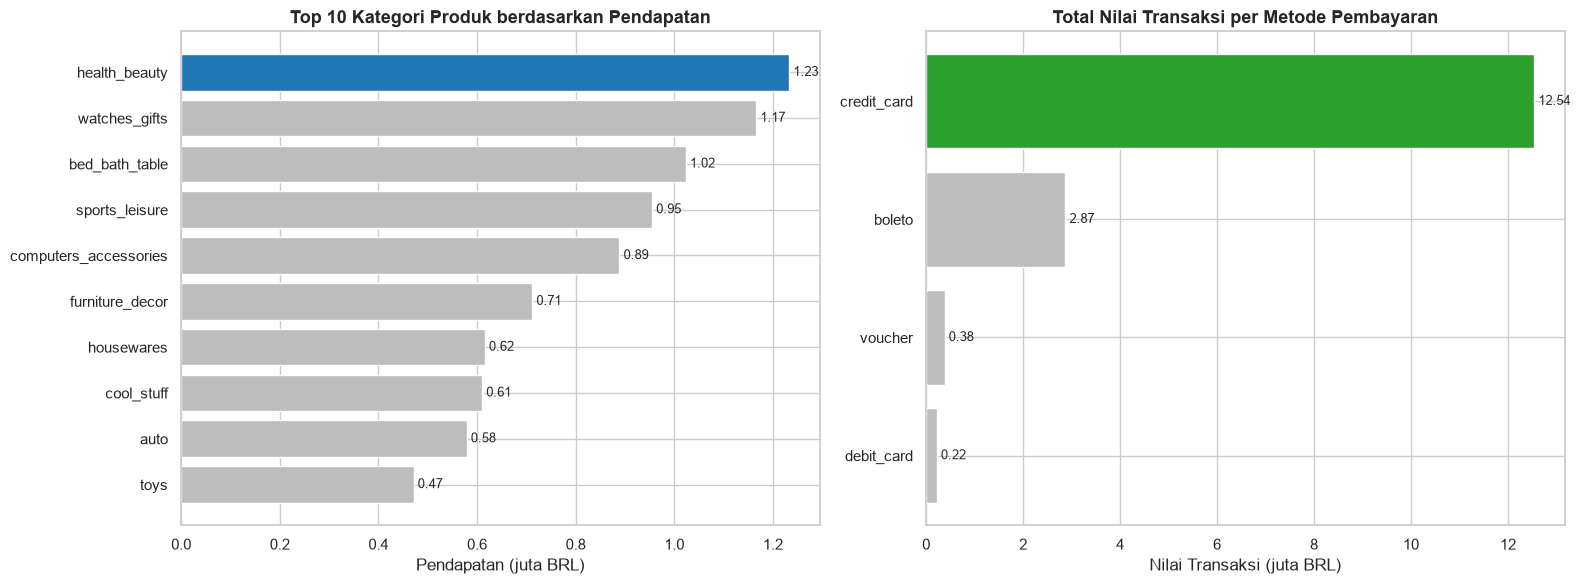

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Viz 1a: Top 10 kategori -- highlight #1
top10 = cat_rev.head(10).sort_values()
colors = ["#bdbdbd"] * len(top10)
colors[-1] = "#1f77b4"  # highlight kategori teratas
ax[0].barh(top10.index, top10.values / 1e6, color=colors)
ax[0].set_title("Top 10 Kategori Produk berdasarkan Pendapatan")
ax[0].set_xlabel("Pendapatan (juta BRL)")
ax[0].bar_label(ax[0].containers[0], fmt="%.2f", padding=3, fontsize=9)

# Viz 1b: komposisi metode pembayaran -- highlight dominan
pr = pay_rev[pay_rev.index != "not_defined"]["sum"].sort_values()
colors2 = ["#bdbdbd"] * len(pr)
colors2[-1] = "#2ca02c"
ax[1].barh(pr.index, pr.values / 1e6, color=colors2)
ax[1].set_title("Total Nilai Transaksi per Metode Pembayaran")
ax[1].set_xlabel("Nilai Transaksi (juta BRL)")
ax[1].bar_label(ax[1].containers[0], fmt="%.2f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

**Penjelasan Visualisasi P1:** Panel kiri menyoroti **health_beauty** sebagai kategori pendapatan tertinggi (disorot biru); tujuh dari sepuluh kategori teratas berselisih tipis sehingga portofolio pendapatan relatif menyebar. Panel kanan menegaskan **credit_card** (disorot hijau) sebagai tulang punggung pembayaran — selisihnya ~4× lipat dibanding boleto.

### Pertanyaan 2: Lama pengiriman vs skor review, dan keterlambatan per provinsi

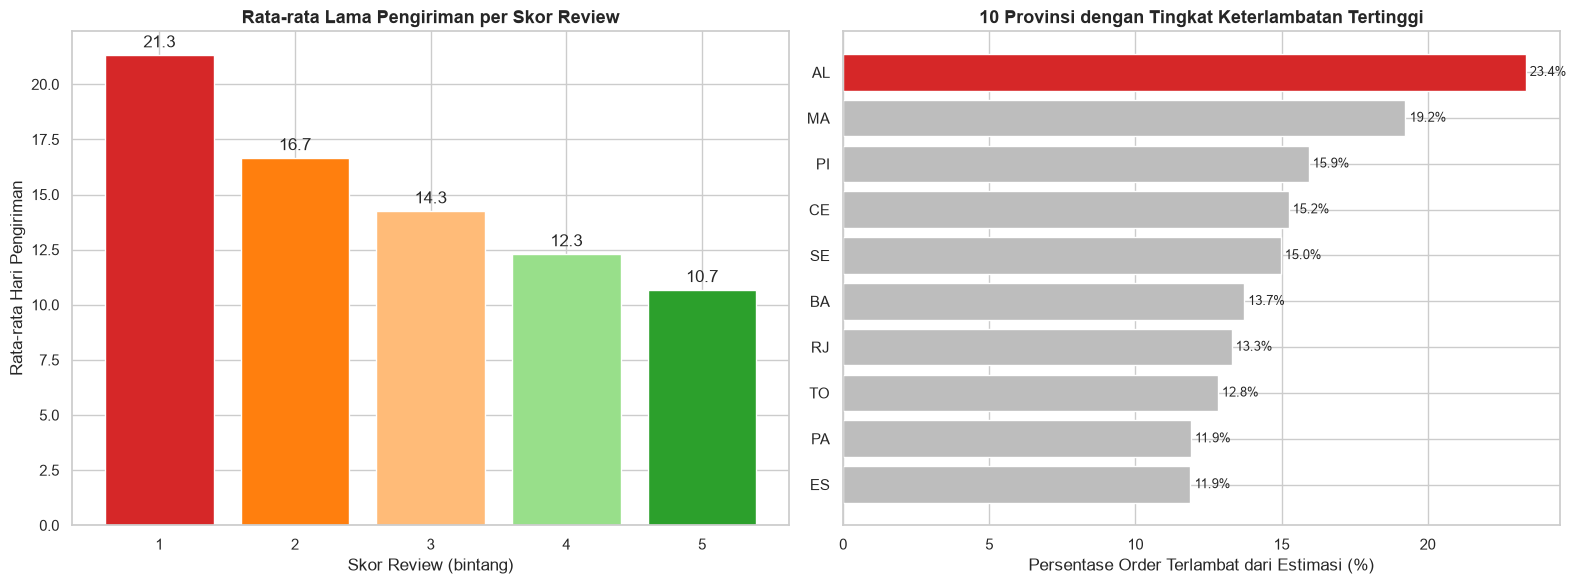

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# Viz 2a: rata-rata hari pengiriman per skor review
mean_days = dv.groupby("review_score")["delivery_days"].mean()
bars = ax[0].bar(mean_days.index.astype(int).astype(str), mean_days.values,
                 color=["#d62728", "#ff7f0e", "#ffbb78", "#98df8a", "#2ca02c"])
ax[0].set_title("Rata-rata Lama Pengiriman per Skor Review")
ax[0].set_xlabel("Skor Review (bintang)")
ax[0].set_ylabel("Rata-rata Hari Pengiriman")
ax[0].bar_label(bars, fmt="%.1f", padding=3)

# Viz 2b: top 10 state by late_rate
sl = state_late.head(10)["late_rate"].sort_values()
colors = ["#bdbdbd"] * len(sl)
colors[-1] = "#d62728"
ax[1].barh(sl.index, sl.values * 100, color=colors)
ax[1].set_title("10 Provinsi dengan Tingkat Keterlambatan Tertinggi")
ax[1].set_xlabel("Persentase Order Terlambat dari Estimasi (%)")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.show()

**Penjelasan Visualisasi P2:** Panel kiri memperlihatkan gradien warna merah→hijau: makin cepat pengiriman, makin tinggi skor — order bintang 5 dikirim rata-rata hampir **2× lebih cepat** daripada bintang 1. Panel kanan menyoroti **AL (Alagoas)** sebagai provinsi dengan proporsi keterlambatan tertinggi (~23%, disorot merah), diikuti provinsi Timur Laut lain.

## Analisis Lanjutan (Tanpa Machine Learning)

Untuk memperkuat analisis, diterapkan **tiga** teknik lanjutan yang relevan dengan dataset: **RFM Analysis**, **Geospatial Analysis**, dan **Manual Clustering (Binning)**.

### 1. RFM Analysis — Segmentasi Pelanggan
**Tujuan:** mengelompokkan pelanggan berdasarkan **Recency** (hari sejak pembelian terakhir), **Frequency** order, dan **Monetary** (total belanja) agar tim pemasaran bisa memprioritaskan pelanggan bernilai tinggi.

In [17]:
snapshot = base["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm = (base.groupby("customer_unique_id")
       .agg(recency=("order_purchase_timestamp", lambda s: (snapshot - s.max()).days),
            frequency=("order_id", "nunique"),
            monetary=("payment_value", "sum")).reset_index())

rfm["R_score"] = pd.qcut(rfm["recency"], 4, labels=[4, 3, 2, 1]).astype(int)
rfm["F_score"] = pd.qcut(rfm["frequency"].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_score"] = pd.qcut(rfm["monetary"], 4, labels=[1, 2, 3, 4]).astype(int)
rfm["RFM_sum"] = rfm[["R_score", "F_score", "M_score"]].sum(axis=1)

def segment(x):
    if x >= 10: return "Champions"
    if x >= 8:  return "Loyal"
    if x >= 6:  return "Potential"
    if x >= 4:  return "At Risk"
    return "Hibernating"
rfm["segment"] = rfm["RFM_sum"].apply(segment)
print(rfm["segment"].value_counts())
rfm.head()

segment
Potential      31942
Loyal          31096
Champions      15245
At Risk        13548
Hibernating     1519
Name: count, dtype: int64


,customer_unique_id,recency,frequency,monetary,R_score,F_score,M_score,RFM_sum,segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,3,8,Loyal
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,3,1,1,5,At Risk
2,0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,4,At Risk
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,4,At Risk
4,0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4,7,Potential


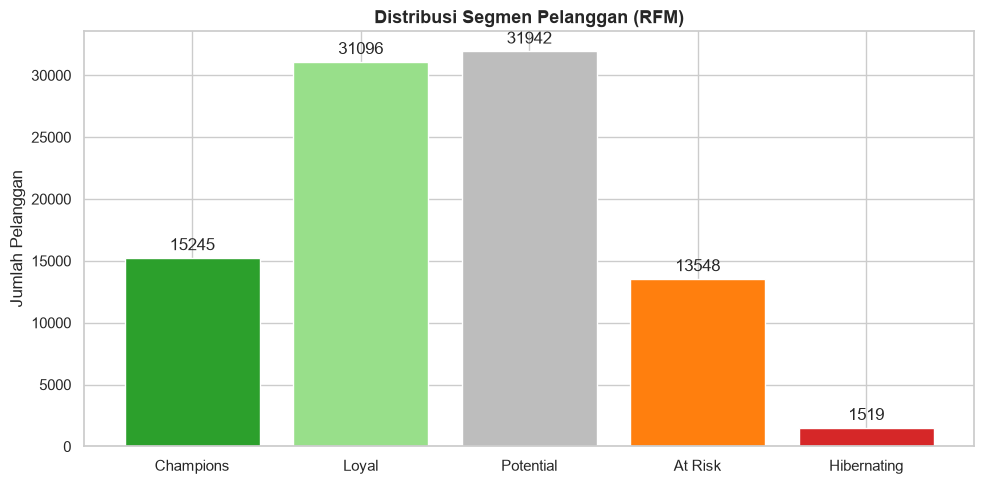

In [18]:
seg_order = ["Champions", "Loyal", "Potential", "At Risk", "Hibernating"]
seg_count = rfm["segment"].value_counts().reindex(seg_order)
colors = ["#2ca02c", "#98df8a", "#bdbdbd", "#ff7f0e", "#d62728"]
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(seg_count.index, seg_count.values, color=colors)
ax.set_title("Distribusi Segmen Pelanggan (RFM)")
ax.set_ylabel("Jumlah Pelanggan")
ax.bar_label(bars, fmt="%d", padding=3)
plt.tight_layout(); plt.show()

**Insight RFM:** Mayoritas pelanggan berada di segment **Potential** dan **Loyal**, dengan **15.245 Champions** yang layak diprioritaskan untuk program loyalitas. Perlu dicatat: `frequency` rata-rata ≈ 1, sehingga skor Monetary & Recency menjadi pembeda utama antar-segmen.

### 2. Geospatial Analysis — Sebaran Order per Provinsi
**Tujuan:** memetakan konsentrasi order secara geografis untuk mengidentifikasi wilayah dengan permintaan tertinggi dan peluang ekspansi.

In [19]:
state_geo = (base.merge(geo_zip, left_on="customer_zip_code_prefix",
                        right_on="geolocation_zip_code_prefix", how="left")
             .groupby("customer_state")
             .agg(orders=("order_id", "count"), revenue=("payment_value", "sum"),
                  lat=("lat", "mean"), lng=("lng", "mean")).reset_index())
state_geo = state_geo.dropna(subset=["lat", "lng"]).sort_values("orders", ascending=False)
state_geo.head()

,customer_state,orders,revenue,lat,lng
25,SP,40494,5769081.27,-23.164977,-47.050482
18,RJ,12350,2055690.45,-22.752311,-43.173027
10,MG,11354,1819277.61,-19.917757,-44.441808
22,RS,5344,861608.40,-29.712516,-51.947265
17,PR,4923,781919.55,-24.784853,-50.791239


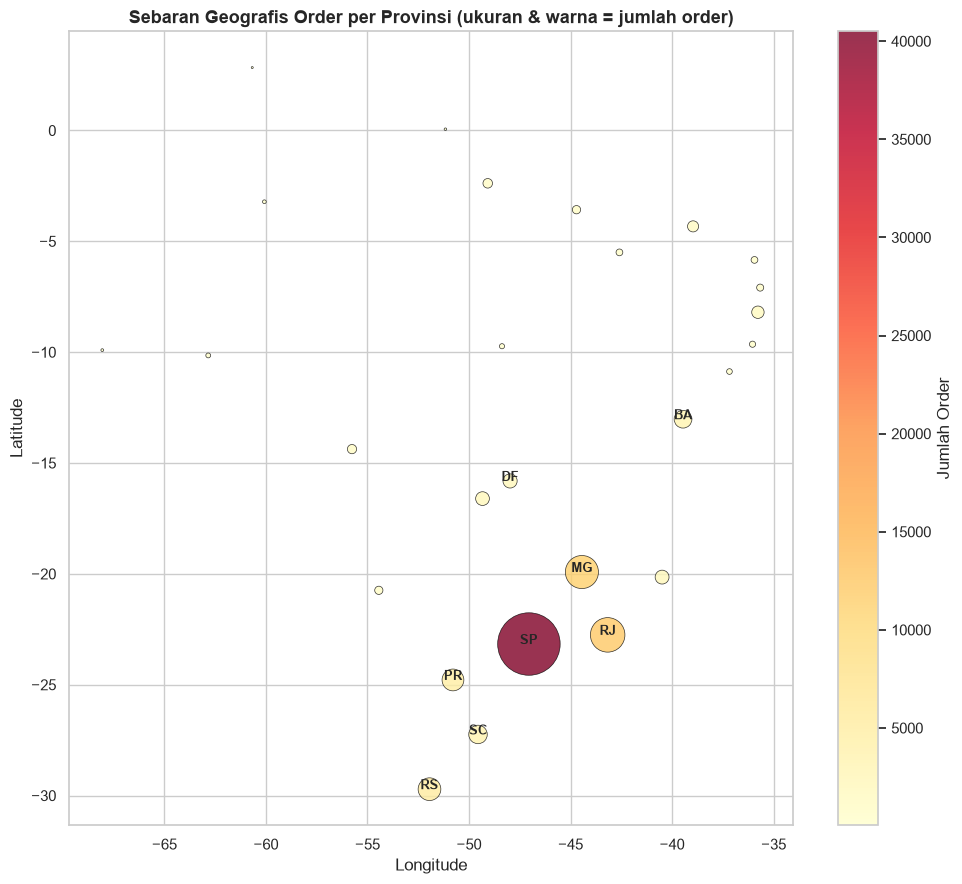

In [20]:
fig, ax = plt.subplots(figsize=(10, 9))
sc = ax.scatter(state_geo["lng"], state_geo["lat"],
                s=state_geo["orders"] / 20, c=state_geo["orders"],
                cmap="YlOrRd", alpha=0.8, edgecolors="black", linewidths=0.5)
for _, r in state_geo.iterrows():
    if r["orders"] > 2000:
        ax.annotate(r["customer_state"], (r["lng"], r["lat"]),
                    fontsize=9, fontweight="bold", ha="center")
ax.set_title("Sebaran Geografis Order per Provinsi (ukuran & warna = jumlah order)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.colorbar(sc, label="Jumlah Order")
plt.tight_layout(); plt.show()

**Insight Geospatial:** Order sangat fokus di **tenggara Brazil**, dipimpin **São Paulo (SP)** dengan **±40.000 order** — lebih dari 3× provinsi terbesar berikutnya (RJ, MG). Wilayah Utara & Timur Laut sangat tipis, konsisten dengan tingginya keterlambatan di sana (temuan P2): jarak dari pusat logistik menekan volume sekaligus kualitas layanan.

### 3. Manual Clustering (Binning) — Kelompok Kecepatan Pengiriman
**Tujuan:** mengelompokkan order ke dalam kategori kecepatan pengiriman dengan `pd.cut`, lalu menilai dampaknya pada rata-rata skor review.

In [21]:
dv["delivery_bucket"] = pd.cut(
    dv["delivery_days"], bins=[-0.1, 3, 7, 14, 30, 400],
    labels=["<=3 hari\n(Sangat Cepat)", "4-7 hari\n(Cepat)", "8-14 hari\n(Normal)",
            "15-30 hari\n(Lambat)", ">30 hari\n(Sangat Lambat)"])
bucket = dv.groupby("delivery_bucket", observed=True).agg(
    orders=("order_id", "count"), avg_score=("review_score", "mean"))
print(bucket.round(3))

                           orders  avg_score
delivery_bucket                             
<=3 hari\n(Sangat Cepat)     4733      4.483
4-7 hari\n(Cepat)           21200      4.404
8-14 hari\n(Normal)         39997      4.312
15-30 hari\n(Lambat)        25464      3.975
>30 hari\n(Sangat Lambat)    4430      2.253


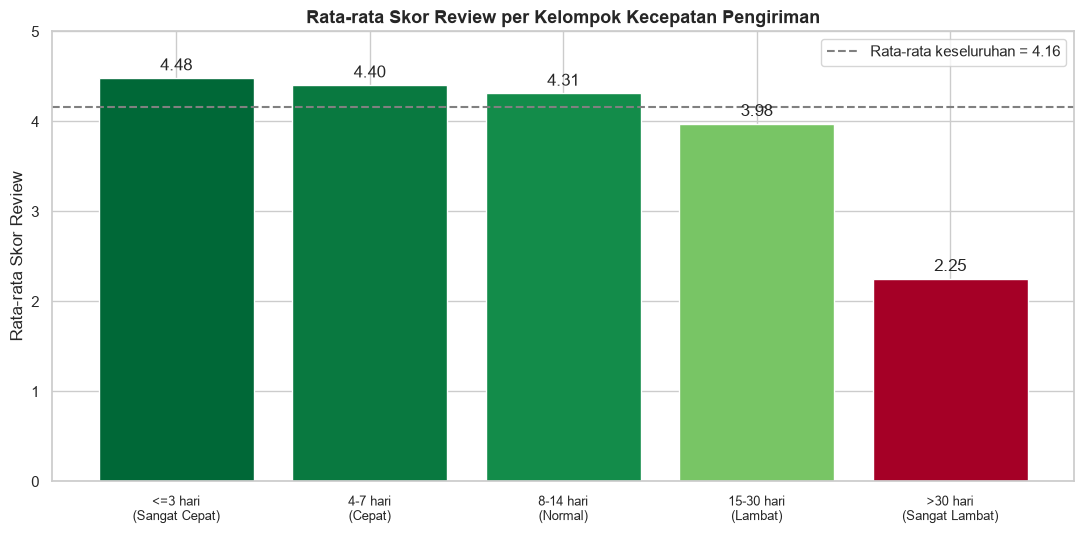

In [22]:
fig, ax = plt.subplots(figsize=(11, 5.5))
norm = plt.Normalize(bucket["avg_score"].min(), bucket["avg_score"].max())
bar_colors = plt.cm.RdYlGn(norm(bucket["avg_score"].values))
bars = ax.bar(range(len(bucket)), bucket["avg_score"], color=bar_colors)
ax.set_xticks(range(len(bucket)))
ax.set_xticklabels(bucket.index, fontsize=9)
ax.set_ylim(0, 5)
ax.axhline(dv["review_score"].mean(), ls="--", color="gray",
           label=f"Rata-rata keseluruhan = {dv['review_score'].mean():.2f}")
ax.set_title("Rata-rata Skor Review per Kelompok Kecepatan Pengiriman")
ax.set_ylabel("Rata-rata Skor Review")
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.legend()
plt.tight_layout(); plt.show()

**Insight Binning:** Hubungan sangat tegas dan menurun monoton. Order **≤3 hari** meraih skor **4,48**, sementara order **>30 hari** anjlok ke **2,25** — turun lebih dari 2 poin penuh. Titik jatuh paling tajam terjadi saat pengiriman melewati **14 hari** (Normal 4,31 → Lambat 3,98 → Sangat Lambat 2,25), menjadikan 14 hari sebagai ambang SLA kritis.

## Conclusion

**Kesimpulan Pertanyaan 1 Kategori & Metode Pembayaran**
Pendapatan Olist dipimpin kategori **health_beauty**, **watches_gifts**, dan **bed_bath_table** (masing-masing > 1 juta BRL), dengan portofolio yang menyebar di sepuluh besar. Dari sisi pembayaran, **kartu kredit mendominasi** (±12,5 juta BRL / ~76 ribu order), hampir 4× lipat boleto; debit dan voucher kontribusinya minim. Marketplace sangat bergantung pada kelancaran pembayaran kartu kredit.

**Kesimpulan Pertanyaan 2 — Pengiriman & Kepuasan**
Lama pengiriman berhubungan **negatif** dengan kepuasan (korelasi **-0,33**): order bintang 5 dikirim rata-rata **10,7 hari**, sedangkan bintang 1 mencapai **21,3 hari**. Keterlambatan di provinsi **Timur Laut** (Alagoas 23%, Maranhão 19%) yang jauh dari pusat logistik São Paulo. Analisis binning menegaskan **14 hari** sebagai batas kritis — melewatinya, skor anjlok drastis hingga 2,25 di kelompok >30 hari.

**Rekomendasi Action Item**
1. **Perketat SLA pengiriman ke batas 14 hari**, terutama untuk provinsi Timur Laut (AL, MA, PI, CE): tambah mitra kurir regional atau gudang/hub distribusi di wilayah ini untuk menekan `late_rate` yang mencapai ~23%. Ini menyasar langsung pengungkit kepuasan terbesar.
2. **Jaga & optimalkan jalur kartu kredit** (promo cicilan, keandalan gateway) karena menjadi tulang punggung ~80% nilai transaksi; sekaligus luncurkan program loyalitas untuk **15.245 pelanggan Champions** hasil segmentasi RFM guna mendorong pembelian berulang (frekuensi rata-rata saat ini hanya ≈1).
